# Geothermal Energy

The interactive controls described in this notebook are available in the [online course lesson](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md); they are not embedded in this standalone notebook.

## Learning goals

After this lesson you should be able to:

- distinguish geothermal gradient, heat flux, thermal power, gross electrical power, and net electrical power;
- use Kelvin correctly in thermodynamic efficiency calculations;
- estimate heat carried by produced fluid;
- include conversion efficiency, parasitic load, and production decline;
- implement validated Python functions and scenario plots;
- explain why temperature alone does not establish a viable geothermal resource.

Electricity generation requires useful heat plus a way to transport it to the surface. Conventional hydrothermal systems rely on heat, fluid, and permeability. Enhanced geothermal systems create or improve fluid pathways, while closed-loop systems circulate fluid in sealed wells [U.S. Department of Energy, 2014](#reference-doeGeothermalElectricity); [U.S. Department of Energy, 2014](#reference-doeEGS). Dry steam, flash steam, and binary-cycle plants use different surface processes and operating ranges. For further reading on emerging geothermal technologies, see the U.S. Department of Energy’s [Pathways to Commercial Liftoff: Next-Generation Geothermal Power (March 2024)](https://cdn.catf.us/wp-content/uploads/2025/06/09154348/doe-liftoff-nextgen-geothermal.pdf), hosted by Clean Air Task Force.

## Comparing geothermal flow paths

The four schematic views compare hydrothermal and enhanced geothermal circulation through rock with U-shaped and coaxial sealed loops. In the EGS view, switch off **Fractures connect both wells** to explore an interrupted pathway. The animations illustrate geometry and connectivity; they do not simulate a measured reservoir.

Open the interactive [flow-path comparison](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-closed-systems), [conduction](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-closed-conduction), [coaxial flow areas](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-closed-area), [thermal energy and available work](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-closed-energy), or [performance](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-closed-performance) view.

## Closed-loop designs: U-shaped and coaxial

In a **closed-loop geothermal system**, a working fluid circulates inside sealed conduits and exchanges heat with the surrounding formation. In an ideal sealed loop the circulating fluid does not enter the formation; heat transfer through the borehole wall and rock is central. This differs from hydrothermal production and injection, where reservoir fluid flows through the rock. White et al. study both water and supercritical CO₂, a range of geometries and operating conditions, and both direct heat use and electricity production [White et al., 2024](#reference-white2024closedloop). Where groundwater is mobile, it can also carry heat through the formation outside the sealed well. This is distinct from the loop fluid entering the rock; the effect depends on the formation and flow. A [numerical study of a U-shaped well in a sedimentary aquifer](https://doi.org/10.1186/s40517-025-00363-4) examines that advective contribution. The conduction-only model described below does not include it.

![Conceptual comparison of U-shaped and coaxial closed-loop geothermal paths](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/generated/assets/images/geothermal-closed-loop-configurations.svg)

*Original teaching schematic, not to scale.* Blue indicates the cooler inlet path and red the warmer outlet path. The coaxial drawing illustrates inlet flow down the annulus and return through the inner tube; other flow directions are possible. The paper's Figure 2 shows its corresponding axisymmetric numerical domains, conductive material and model boundaries. Its segmented rock domains are coupled through the circulating fluid; this schematic does not reproduce their numerical mesh [White et al., 2024](#reference-white2024closedloop).

| Feature | U-shaped | Coaxial (pipe-in-pipe) |
|---|---|---|
| Flow path | Separate descending and ascending legs joined at depth | Inner tube and surrounding annulus provide opposing paths inside a borehole |
| Heat exchange | Working fluid exchanges heat along the loop; insulation can reduce unwanted heat loss | Heat exchange with the rock competes with thermal short-circuiting between the inner and outer streams |
| Hydraulic trade-off | Pressure losses depend on length, diameter, fluid and rate | Smaller available flow passages can create large pressure losses at high rates |
| Design choices | Depth, lateral length, diameter, insulation and possibly multiple laterals | Those choices plus inner/outer diameters, pipe insulation and flow direction |

Parallel laterals can thermally interfere when their cooled regions overlap; the effect depends on spacing, geology and operating history. White et al.'s illustrative multi-lateral scaling assumes enough separation to avoid interference, so it does not quantify the effect for an arbitrary spacing [White et al., 2024](#reference-white2024closedloop), §3.3.4. In a coaxial well, heat can also pass between the inner return and surrounding inlet streams; insulation and flow direction affect that exchange.

### Heat transfer, flow area and useful energy

For a homogeneous solid with constant properties and conduction as the only transport process, the transient formation temperature $T$ obeys

$$\rho_r c_r\frac{\partial T}{\partial t}=k_T\nabla^2T, \qquad \alpha=\frac{k_T}{\rho_r c_r}.$$

$k_T$ is rock thermal conductivity in W/(m K), $\rho_r$ is density in kg/m³, $c_r$ is specific heat in J/(kg K), and thermal diffusivity $\alpha$ is in m²/s. In hot dry rock, fluid extraction cools rock near the borehole; heat must conduct from farther away, so outlet temperature can decline rapidly at first and more slowly later. The paper discusses $k_T/\sqrt{\alpha}$, a thermal effusivity in J/(m² K s$^{1/2}$), as a relevant rock property. In words, effusivity here is thermal conductivity divided by the square root of thermal diffusivity. A real model must couple the fluid, pipe and formation with appropriate geometry and boundaries; this equation alone is not a closed-loop solution [White et al., 2024](#reference-white2024closedloop).

The conduction explorer uses an idealized one-dimensional semi-infinite solid and a fixed wall temperature. It illustrates the equation's heat-diffusion boundary, not the full well or groundwater model.

For concentric tubes, let $D_i$ be the inside diameter of the inner tube, $D_o$ its outside diameter, and $D_b$ the inside diameter of the surrounding flow passage. Then

$$A_{tube}=\frac{\pi D_i^2}{4},\qquad A_{annulus}=\frac{\pi(D_b^2-D_o^2)}{4},\qquad \frac{A_{annulus}}{A_{tube}}=\frac{D_b^2-D_o^2}{D_i^2}.$$

Use consistent diameter definitions and units. For example, $D_i=0.10$ m, $D_o=0.12$ m and $D_b=0.18$ m give an annulus-to-tube area ratio of **1.8**. Smaller passages may increase velocity and pressure losses for a given mass flow; their full evaluation requires fluid properties, roughness, elevation and a hydraulic model.

At the fluid boundary, the paper defines thermal energy and an idealized maximum available work over time as

$$E_{thermal}=\int_0^\tau\dot m(h_{out}-h_{in})\,dt, \qquad E_{available}=\int_0^\tau\dot m[(h_{out}-h_{in})-T_{amb}(s_{out}-s_{in})]\,dt.$$

Here $h$ is specific enthalpy (J/kg), $s$ is specific entropy (J/(kg K)), $\dot m$ is kg/s and ambient temperature $T_{amb}$ is in kelvin. These expressions use the inlet/outlet states and reference in the paper; actual net generation also depends on the conversion plant and auxiliaries. The constant-$c_p$ expression elsewhere in this lesson is a liquid-water approximation; it must not replace property-based enthalpy and entropy for supercritical CO₂ or phase change [White et al., 2024](#reference-white2024closedloop).

The following explorer treats the enthalpy and entropy differences as constant teaching inputs. Obtain consistent fluid properties before using this relation for a real system; the available-work result is signed.

### What did the paper find?

The attached outlet-temperature plot corresponds to **two U-shaped water cases**, not a U-shaped versus coaxial comparison. Both use a 10 km lateral and the same Utah FORGE-based rock and depth; the curves differ in both mass flow and insulation length: **11.8 kg/s with 1,174 m insulation**, and **38 kg/s with 875 m insulation**. Four modeling approaches show close agreement in Figure 3. Their differences cannot be attributed to flow rate alone [White et al., 2024](#reference-white2024closedloop).

For a comparison of both geometries and working fluids, the paper's Table 3 reports four independently selected electricity cases over 40 years. Each uses 5 km depth, 0.4445 m borehole diameter, 0.07 °C/m gradient, 4.5 W/(m K) conductivity, 60 °C inlet, a 7% discount rate and the paper's \$1,000/m drilling cost assumption. These are hypothetical extremes of the study’s parameter range, not typical sites. The 20 km extent reaches the database’s horizontal-length limit, and the U-shaped CO₂ case reaches its 100 kg/s flow limit; its flow is not a proven unconstrained optimum. Reported costs exclude items including exploration, redrilling, well-field maintenance and land leasing, so they are not a complete project budget.

| Reported quantity | U-shaped water | Coaxial water | U-shaped supercritical CO₂ | Coaxial supercritical CO₂ |
|---|---:|---:|---:|---:|
| Selected mass flow (kg/s) | 43.0 | 39.2 | 100 | 69.6 |
| Horizontal extent (km) | 20 | 20 | 20 | 13 |
| Average production temperature (°C) | 205 | 203 | 190 | 174 |
| Average thermal production (MW thermal) | 26.0 | 23.8 | 22.2 | 14.1 |
| Average electricity generation (MW electric) | 3.9 | 3.5 | 5.0 | 2.8 |
| Reported LCOE (USD/MWh electric) | 96.6 | 93.5 | 83.0 | 86.9 |

These are modeled averages and costs under the study assumptions, not forecasts or measurements. The different flow rates and design details mean this table does **not** isolate geometry at identical operating conditions; the CO₂ cases use a different surface conversion cycle. Nor does it establish a universal winner. For a more representative coaxial water example, the authors report 3 W/(m K), a 45 °C/km gradient and approximately 37 kg/s, producing an average 130 °C outlet and 0.922 MW electric under their other stated assumptions. See Table 3 and §3.3.1 for the complete parameter context [White et al., 2024](#reference-white2024closedloop).

The paper expresses levelized costs using discounted annual costs and discounted annual energy, for example

$$LCOE=\frac{\sum_t(C_t+O_t)/(1+r)^t}{\sum_t E_{e,t}/(1+r)^t}.$$

$C_t$ and $O_t$ are capital and operating costs, $E_{e,t}$ is electrical energy and $r$ is the discount rate. The paper's displayed sums begin at year 1. For a general cash-flow model, include an initial $t=0$ investment if it occurs at project start, and include each cost and energy period once; this is an additional timing convention rather than a claim about the paper's displayed limits. LCOE is not electricity-sale revenue, and its assumptions differ from the Field Designer's simple cumulative game balance. White et al.'s GeoCLUSTER results are accessible through the [Geothermal Data Repository](https://gdr.openei.org/submissions/1473); interpolation and inputs are subject to the paper's stated limitations.

The performance explorer displays rounded Figure 3 readings and the four Table 3 cases. Its separate LCOE calculator uses its own stated teaching assumptions, including upfront capital and year-end energy; it is not a reproduction of all the paper's cost assumptions.

,Configuration,Flow (kg/s),Thermal (MW),Electric (MW),LCOE (USD/MWh)
0,U-shaped water,43.0,26.0,3.9,96.6
1,Coaxial water,39.2,23.8,3.5,93.5
2,U-shaped CO₂,100.0,22.2,5.0,83.0
3,Coaxial CO₂,69.6,14.1,2.8,86.9


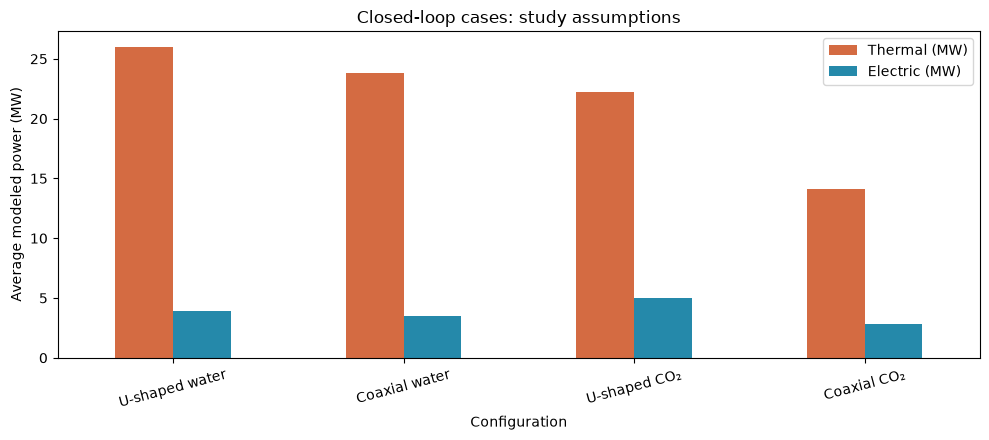

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# White et al. (2024), Table 3: independently selected electricity cases.
comparison = pd.DataFrame({
    'Configuration': ['U-shaped water', 'Coaxial water', 'U-shaped CO₂', 'Coaxial CO₂'],
    'Flow (kg/s)': [43.0, 39.2, 100.0, 69.6],
    'Thermal (MW)': [26.0, 23.8, 22.2, 14.1],
    'Electric (MW)': [3.9, 3.5, 5.0, 2.8],
    'LCOE (USD/MWh)': [96.6, 93.5, 83.0, 86.9],
})
ax = comparison.plot.bar(x='Configuration', y=['Thermal (MW)', 'Electric (MW)'],
                         color=['#d46b42', '#2589aa'], figsize=(10, 4.5), rot=15)
ax.set(ylabel='Average modeled power (MW)', title='Closed-loop cases: study assumptions')
plt.tight_layout()
comparison

<!-- expanded-theory:geothermal:start -->

## Physical description: useful heat from the subsurface

Geothermal energy is thermal energy in the Earth. A geothermal project does not produce energy merely by drilling to a high temperature: it needs a technically usable heat resource, a way to transfer heat to the surface, a suitable conversion or direct-use system, and an operating strategy that manages the subsurface response. Temperature, accessible fluid flow, pressure, chemistry and permeability all matter [Grant & Bixley, 2011](#reference-grant2011).

Heat within the Earth includes contributions from its formation and radioactive decay. At a local project scale, however, the important question is how heat reaches and is stored in the reservoir and how quickly it can be extracted. Natural replenishment does not guarantee that a particular well field can support an arbitrary extraction rate. Some systems can be operated for long periods, while excessive drawdown, cooling or fluid-management problems can limit output. [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.5.

### Resource and utilization categories

| System or use | Description | Consequence for modelling |
|---|---|---|
| Hydrothermal resource | Naturally occurring hot fluid in permeable rock | Need reservoir pressure, temperature, flow pathways and fluid properties |
| Enhanced geothermal system (EGS) | Improves or creates fluid pathways in hot rock | Hydraulic connectivity, stimulation response and reservoir management become central |
| Closed-loop subsurface system | Circulates a working fluid through sealed underground conduits | Heat transfer through the well and surrounding formation can constrain output |
| Direct heat use | Delivers heat to a suitable process, building or heat network | Calculate useful thermal energy at the delivery temperature, not electrical output |
| Geothermal power generation | Converts a portion of extracted heat into electricity | Include cycle efficiency, cooling and parasitic electricity consumption |
| Ground-source heat pump | Uses the ground as a heat source or sink with electrical compressor work | Track electricity input and heat delivery; this is not geothermal electricity generation |

*Sources for these definitions:* [Grant & Bixley, 2011](#reference-grant2011), Chapter 2; [U.S. Department of Energy, 2014](#reference-doeEGS); [U.S. Department of Energy, 2014](#reference-doeGeothermalElectricity). Heat-pump accounting: [OpenStax, University Physics 2, §4.3](https://openstax.org/books/university-physics-volume-2/pages/4-3-refrigerators-and-heat-pumps).

The following resource settings illustrate why temperature alone is insufficient [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.5:

| Resource setting | Assessment implication |
|---|---|
| Warm groundwater or sedimentary aquifer | Check productive flow, temperature and the needs of the heat customer. |
| Fault-controlled warm spring | A spring indicates a possible flow path; it does not by itself establish well deliverability. |
| Geopressured formation | High fluid pressure, brine chemistry and any dissolved-gas handling affect development. |
| Hot low-permeability rock | The extraction design must provide sufficient heat-transfer area and, for EGS, connected fluid pathways. |
| Liquid- or vapor-dominated convective reservoir | Phase distribution, pressure and changes during production affect the operating strategy. |

Reservoir descriptions and end uses answer different questions. Grant and Bixley distinguish conductive settings from liquid-dominated and vapor-dominated convective reservoirs. Liquid can be the principal mobile phase even when some steam is present; a vapor-dominated system can still contain liquid. A magmatic heat source does not mean that the circulating fluid travels through magma [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.5. A project may use its heat directly, generate electricity, or supply both. **Coproduction** recovers heat from hot fluids brought to the surface during active oil or gas production; the heat may support electricity or direct use where suitable. See [DOE, Wells of Opportunity](https://www.energy.gov/hgeo/geothermal/wells-opportunity). Research into **superhot geothermal** includes enhanced and closed-loop approaches, but the high-temperature conditions create materials, well-construction and operating challenges; a research target is not a guarantee of commercial performance. See [ARPA-E, SUPERHOT](https://arpa-e.energy.gov/programs-and-initiatives/view-all-programs/superhot).

Ground-source heat pumps are a separate end-use technology from deep geothermal electricity systems. Their heat exchangers can use horizontal, vertical or pond/lake closed loops, or an open loop using water from a well or surface source; site and water conditions affect the choice. See the [DOE consumer guide, system types](https://www.energy.gov/sites/default/files/2021-08/ES-Geothermal%20heat%20pumps_080221.pdf).

Hydrothermal and EGS are typical design descriptions rather than mutually exclusive categories: stimulation can improve or expand an already productive hydrothermal system ([DOE induced-seismicity protocol](https://www1.eere.energy.gov/geothermal/pdfs/geothermal_seismicity_protocol_012012.pdf)). Hydrothermal, EGS and closed-loop describe aspects of the subsurface system; dry-steam, flash and binary describe surface electricity-conversion arrangements. These classifications answer different questions and should not be used interchangeably. The supplied Grant and Bixley book develops reservoir concepts and simplified models; DiPippo is additional reading for power-conversion systems [Grant & Bixley, 2011](#reference-grant2011); [DiPippo, 2016](#reference-diPippo2016geothermal).

## Reservoir terms and transport processes

**Porosity** is the fraction of bulk rock volume occupied by pores or voids. **Permeability** describes the medium's ability to transmit fluid; connected pathways matter, so high porosity alone does not guarantee a productive well. Fractures can dominate fluid flow even when matrix permeability is low. **Transmissivity** incorporates the ability of a formation interval to transmit fluid over its effective thickness and depends on the convention used. [Grant & Bixley, 2011](#reference-grant2011), §§2.3–2.5, §3.3.1 and §3.7.

For a homogeneous saturated layer, hydrogeological hydraulic transmissivity is $Kh$ in m²/s, where $K$ is hydraulic conductivity and $h$ is saturated thickness. Grant and Bixley also use mobility-thickness $kh/\mu$, with different units, m³/(Pa s). For constant-density single-phase fluid, $K=k\rho g/\mu$, so $Kh=\rho g(kh/\mu)$; the numerical values are not interchangeable. Here $k$ is intrinsic permeability, $\rho$ fluid density, $g$ gravity and $\mu$ dynamic viscosity. See [USGS on hydraulic transmissivity](https://pubs.usgs.gov/wsp/2220/report.pdf) and [Grant & Bixley, 2011](#reference-grant2011), §3.3.1.

**Reservoir pressure** helps drive fluid toward a producing well, while pressure decline can reduce deliverability or increase pumping requirements. **Production wells** bring fluid to the surface; **injection wells** return fluid or supply circulation. Injection can help manage fluid mass and pressure, but poorly placed or strongly connected injection can cause premature cooling at producers. **Thermal breakthrough** is the arrival of a cooling influence along flow paths, not simply the passage of one calendar year [Grant & Bixley, 2011](#reference-grant2011).

A conceptual fluid-flow relationship is Darcy's law. For a one-dimensional horizontal, single-phase flow without a gravity term,

$$q_D=-\frac{k_{perm}}{\mu}\frac{dp}{dx}.$$

$q_D$ is Darcy flux in m/s, $k_{perm}$ is intrinsic permeability in m², $\mu$ is dynamic viscosity in Pa s, and $dp/dx$ is pressure gradient in Pa/m. The negative sign represents flow toward decreasing pressure. Actual geothermal flow may involve gravity, temperature-dependent properties, fractures and multiple phases, so this reduced relationship is not a complete well model. It explains why temperature alone cannot establish producible mass flow.

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §3.3.1, Eq. 3.21 (radial single-phase flow), and Appendix §A3.3.1, Eq. A3.10 (vector form including gravity). The expression above applies the stated horizontal, gravity-free simplification.

### Conduction and convection

Conduction transfers heat through a material without bulk transport of that material. Advection carries heat with moving fluid; buoyancy-driven circulating flow is commonly described as convection. In low-permeability conductive regions, a temperature gradient can help estimate deeper temperature over an appropriate interval. In permeable convecting systems, simple downward extrapolation of the shallow gradient may be misleading [Grant & Bixley, 2011](#reference-grant2011).

The linear conductive approximation is $T(z)=T_0+G_Tz$, where the depth coordinate and gradient must use matching units. If depth is in kilometres and gradient in °C/km, the product is a temperature difference in °C. This is a local model, not a universal rule that temperature always rises at one fixed rate everywhere.

Fourier's law is

$$\mathbf q=-k_T\nabla T,$$

where thermal conductivity $k_T$ is W/(m K) and heat flux $\mathbf q$ is W/m². Thermal conductivity and intrinsic permeability are different physical properties; separate symbols help avoid confusion. If depth $z$ is positive downward and temperature rises downward, the conductive heat-flux vector points upward. For conductivity 2.5 W/(m K) and gradient 30 K/km, the upward heat-flux magnitude is $2.5(30/1000)=0.075$ W/m². A gradient is not itself a heat flux.

*Equation basis:* [OpenStax, surface integrals and Fourier’s law](https://openstax.org/books/calculus-volume-3/pages/6-6-surface-integrals) gives the vector relation and identifies thermal conductivity. [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 discuss conductive versus convective profiles. In the Wairakei example on p. 16, the larger quoted heat flux is convective; a later reference to it as conductive appears to be a wording error.

## The surface plant and its energy boundaries

A typical conversion chain is **reservoir → production well → fluid collection/separation or heat exchanger → power cycle → generator → cooling/auxiliaries → reinjection**, with the detailed route depending on fluid state and technology. Pressure losses, pumping work and heat losses occur between reservoir and delivered output. [U.S. Department of Energy, 2014](#reference-doeGeothermalElectricity); reservoir-to-well limits: [Grant & Bixley, 2011](#reference-grant2011), Chapter 2.

### Dry-steam, flash and binary conversion

**Dry-steam plants** use a suitable steam resource to drive a turbine. **Flash plants** reduce the pressure of sufficiently hot liquid so that part of it vaporizes; a separator supplies steam to a turbine while residual liquid follows its own handling or reinjection path. **Binary plants** transfer geothermal heat through an exchanger to a separate working-fluid cycle. The geothermal fluid and the turbine working fluid therefore need not be the same fluid. [U.S. Department of Energy, 2014](#reference-doeGeothermalElectricity); [Grant & Bixley, 2011](#reference-grant2011), Chapter 2.

These plant families describe surface conversion rather than uniquely identifying the subsurface extraction method. Some sites combine flash and binary stages; a binary plant can receive heat from a conventional resource, an engineered reservoir or a closed loop when the fluid and conditions suit its design. See [NREL, geothermal technology description](https://atb.nrel.gov/electricity/2024/geothermal) for hybrid flash–binary plants.

The plant type must match the temperature, pressure, phase state and chemistry of the resource. There is no single efficiency that applies to all geothermal plants. Cooling conditions and auxiliary demand also affect exported electricity. The course's constant-efficiency, single-phase calculation is most useful for learning heat-to-electricity accounting; it is not a detailed flash or binary cycle simulation [Grant & Bixley, 2011](#reference-grant2011); [U.S. Department of Energy, 2014](#reference-doeGeothermalElectricity).

DiPippo's fourth edition is a supplementary textbook covering power-conversion systems and case studies. Its publisher lists a late-2015 release while the copyright/edition page identifies 2016; this course cites the 2016 edition year. Current plant counts should not be inferred from the historical statistics in that edition [DiPippo, 2016](#reference-diPippo2016geothermal).

## Thermal power: mass flow and enthalpy

For a steady heat exchanger with negligible shaft work and changes in kinetic and potential energy, the heat removed from the geothermal stream is

$$\dot Q_{extracted}=\dot m(h_p-h_r),$$

where $\dot m$ is mass flow in kg/s, and $h_p$ and $h_r$ are specific enthalpies at the chosen production and return states. With $h$ in J/kg, output is W; with $h$ in kJ/kg, output is kW. This neglects heat leakage between the specified measurement states and the heat exchanger; it is the heat extracted from the stream under the defined boundary, not necessarily all the stored heat in the reservoir.

*Equation basis:* The [DOE-hosted EGS resource assessment, §3.3.1, p. 3-6](https://www1.eere.energy.gov/geothermal/pdfs/egs_chapter_3.pdf#page=6) describes extraction rate as mass flow times the produced-to-reinjected enthalpy difference. The surface heat-exchanger expression above additionally assumes negligible heat leakage between the selected states. [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6 and [Foster et al., 2010](#reference-foster2010), §3.8.1 provide conservation background.

For a single-phase liquid with approximately constant specific heat,

$$h_p-h_r\approx c_p(T_p-T_r),\qquad
P_{th}=\dot m c_p(T_p-T_r).$$

| Symbol | Definition | Unit used in the course |
|---|---|---|
| $\dot m$ | Produced fluid mass flow | kg/s |
| $c_p$ | Specific heat capacity, approximated as 4180 for water | J/(kg K) |
| $T_p$, $T_r$ | Production and reinjection/return temperatures at specified locations | °C for the difference |
| $h_p$, $h_r$ | Specific enthalpy at the two stream states | J/kg or kJ/kg, explicitly identified |
| $P_{th}$ | Thermal power extracted under the chosen boundary | W or MW thermal |
| $P_{gross}$, $P_{net}$ | Gross generated and net exported electrical power | W or MW electrical |

*Source for the constant-property approximation:* [DOE-hosted EGS report, §B.6, Eq. B-39](https://www1.eere.energy.gov/geothermal/pdfs/jason.final.pdf#page=140). The approximation is for the stated single-phase, approximately constant-heat-capacity boundary.

A temperature difference of 80°C is also 80 K. Absolute temperature ratios, by contrast, require kelvin. Salinity, temperature and pressure affect fluid properties. In two-phase flow, energy includes latent heat and phase fractions; applying one constant liquid-water heat capacity to a steam/water mixture can substantially misrepresent the heat balance [Grant & Bixley, 2011](#reference-grant2011).

## Heat-engine limits, net output and direct heat use

For an ideal reversible engine operating between fixed hot and cold reservoirs,

$$\eta_C=1-\frac{T_c}{T_h},$$

with both absolute temperatures in kelvin. It is an upper bound for that idealized setting, not the efficiency to assign to a plant. A real geothermal stream cools through a temperature range, heat exchangers require finite temperature differences, and real machinery dissipates energy. A full thermodynamic assessment needs the actual cycle and fluid states.

*Sources and assumptions for this equation group:* Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

The introductory model uses

$$P_{gross}=\eta_{conv}P_{th},\qquad
P_{net}=P_{gross}-P_{pump}-P_{aux}.$$

If parasitic consumption is represented as a fraction $f_{par}$ of **gross electrical power**, then $P_{net}=P_{gross}(1-f_{par})$. State that denominator explicitly. Ten percent of gross electricity is not ten percent of thermal input. Net exported power is the boundary used for project energy and capacity-factor calculations.

A simple hydraulic pumping estimate is

$$P_{pump}=\frac{\Delta p\,Q}{\eta_{pump}},$$

where pressure rise is Pa and liquid volume flow is m³/s. To interpret power as electrical input, the dimensionless efficiency must include motor and drive as well as pump losses; a pump-only efficiency yields shaft power and needs a separate motor factor. If $P_{pump}$ is subtracted separately, $P_{aux}$ must exclude that same pumping load, including its motor and drive losses. If a stated parasitic fraction already includes pumping, do not subtract pumping again. Power is W. Use volume flow here, rather than inserting mass flow without dividing by density. Pressure and flow requirements may change during operation, so a fixed parasitic fraction can hide an important source of declining net output.

In direct-use heating, useful thermal output can be delivered without converting it to electricity. The delivery-temperature requirement matters: heat available below the required process temperature is not automatically usable without a heat pump or another upgrade. For a heat pump, heating coefficient of performance is $COP_h=\dot Q_{delivered}/P_{electric}$ and can exceed one because delivered heat includes heat moved from the source as well as electrical input. That does not violate energy conservation and is not an electrical-generation efficiency. [OpenStax, heat pumps and coefficient of performance](https://openstax.org/books/university-physics-volume-2/pages/4-3-refrigerators-and-heat-pumps).

## Reservoir storage, replenishment and production decline

An illustrative sensible-heat inventory for a uniform bulk reservoir volume is

$$E_{heat}\approx V\left[(1-\phi)\rho_r c_r+\phi\rho_f c_f\right](T-T_{ref}).$$

$V$ is bulk volume, $\phi$ porosity, and the subscripts $r$ and $f$ refer to rock and fluid. Use coherent SI units to obtain joules. Rock density is mass per solid-rock volume, while fluid density is mass per fluid volume; the volume fractions are applied explicitly and must not be applied again to already bulk-volume properties. This form assumes the pore volume is fully saturated with the modeled fluid, uniform temperature and properties, and no phase change. It is not a recoverable electrical reserve: only some heat may be technically accessible, extraction occurs over time, and electrical conversion incurs further limitations [Grant & Bixley, 2011](#reference-grant2011).

*Sources and assumptions for this equation group:* [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6 (storage and stored-heat estimates). The compounded/exponential decline equations are stipulated scenarios, not reservoir predictions.

Pressure response, fluid recharge and heat recharge operate on different pathways and time scales. Maintaining pressure by reinjection does not guarantee that production temperature is maintained. Conversely, observing short-term stable output does not prove indefinite sustainability. Reservoir monitoring and calibrated coupled models are needed for long-run operating decisions.

For teaching, a compounded annual power decline is

$$P_y=P_1(1-d)^{y-1}.$$

The exponent is zero in year 1. If $d=0.02$, each subsequent year retains 98% of the preceding year's assumed power. This is different from subtracting two percent of the original power every year. A continuous exponential model $P(t)=P_0e^{-Dt}$ uses a decline constant $D$ with inverse-time units; for annual steps, $D=-\ln(1-d)$ per year.

Fitting $\ln P$ against time requires positive observations and changes the assumed error model. Reserve later observations before fitting, compare against a simple baseline, and report the evaluated period. Intervention, changing flow, outages and reservoir connectivity can invalidate extrapolation. A prescribed or fitted decline curve is not, by itself, a reservoir simulator.

## Energy, availability and operating limits

Integrate net power over the actual duration: $E_{net}=\sum_iP_{net,i}\Delta t_i$. If an annual model specifies net power **when operating** and a separate availability $a$, $E_y=P_y a T_y$ is an appropriate simplified expression. If measured hourly power already includes downtime, multiplying by availability again would double-count it. Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

Use a fixed defined net nameplate $P_{r,net}$ for $CF=E_{net}/(P_{r,net}T)$. Do not use observed maximum output as a substitute unless that is explicitly the intended metric. If a plant has a net power limit, apply it after the resource-to-net-power calculation under the stated boundary. Negative net electricity can physically occur when auxiliaries consume more power than is generated; a model restricted to positive exported generation should state how such operating periods are handled rather than silently changing their meaning. Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

## Worked calculation before coding

Suppose a synthetic liquid-water resource produces 50 kg/s at 150°C and returns at 70°C. Assume $c_p=4180$ J/(kg K), gross conversion efficiency 0.12 and parasitic consumption equal to 10% of gross electricity.

1. Temperature drop is $150-70=80$ K.
2. Thermal power is $50(4180)(80)=16{,}720{,}000$ W, or **16.72 MW thermal**.
3. Gross electricity is $16.72(0.12)=2.0064$ MW.
4. Parasitic demand is $2.0064(0.10)=0.20064$ MW.
5. Net output is $2.0064-0.20064=1.80576$ MW.
6. Four hours at that net output deliver **7.22304 MWh** of electricity.

*Source for these definitions/calculations:* Original numerical substitution with assumed constant properties and efficiencies; Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

The reservoir-to-fluid heat transfer, pressure losses and detailed power-cycle behavior are not solved by these six steps. Their purpose is to make the assumed conversion boundaries visible before implementing arrays and functions.

## Environmental context and the route to Python

Geothermal projects need attention to fluid chemistry, scaling, corrosion, water use, noncondensable gases, injection management, possible subsidence and induced seismicity. The relevance and magnitude of each issue depend on the resource and operating method. Reinjection is not simply waste disposal; it interacts with the hydraulic and thermal behavior of the field [Grant & Bixley, 2011](#reference-grant2011).

Exercises 1–4 cover the Basic skills, Exercises 5–12 apply the models in Medium tasks, and Exercises 13–20 combine models, data, and validation in Hard tasks. Read Grant and Bixley Chapters 2–3 for the reservoir basis; use the additional DiPippo text to extend from the simplified heat balance toward actual surface conversion cycles [Grant & Bixley, 2011](#reference-grant2011); [DiPippo, 2016](#reference-diPippo2016geothermal).

<!-- expanded-theory:geothermal:end -->

## Concepts and equations: compact reference

Use the interactive models for [gradient and heat flux](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-gradient-explorer), [thermal power](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-heat-explorer), [Carnot efficiency](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-carnot-explorer), [conversion to net electricity](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-conversion-explorer), [energy and availability](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-energy-explorer), and [production decline](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section6%2FgeothermalEnergy.md&anchor=geo-decline-explorer).

### Geothermal gradient is not heat flux

A linear temperature-depth approximation is

$$T(z)=T_0+G_Tz$$

where $G_T$ is the geothermal gradient, for example °C/km. This is a local approximation; gradients vary with geology, groundwater flow, and depth.

*Sources and assumptions for this equation group:* [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 (conductive versus convective profiles).

Conductive heat flux follows Fourier's law:

$$\mathbf{q}=-k_T\nabla T$$

The negative sign indicates heat flows toward lower temperature. Gradient (K/m) and heat flux (W/m$^2$) are different quantities.

### Thermal power in produced fluid

For mass-flow rate $\dot m$, specific heat $c_p$, production temperature $T_p$, and reinjection temperature $T_r$:

$$P_{th}=\dot m c_p(T_p-T_r)$$

*Sources and assumptions for this equation group:* Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

If $c_p$ is J/(kg K), the result is W. A constant liquid-water $c_p$ is a simplified sensible-heat model; steam, flashing, brines, and phase change require enthalpy:

$$P_{th}=\dot m(h_p-h_r)$$

### Efficiency, parasitic load, and net power

The reversible Carnot bound is

$$\eta_C=1-\frac{T_c}{T_h}$$

where both temperatures must be in Kelvin. A plant cannot simply be assigned Carnot efficiency; real conversion efficiency is lower and technology-specific.

*Sources and assumptions for this equation group:* Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

$$P_{gross}=\eta_{conv}P_{th}$$

$$P_{net}=P_{gross}-P_{pumps}-P_{aux}$$

Net power, not gross generator power, is the relevant exported power.

### Energy and decline

For discrete time steps:

$$E_{net}=\sum_iP_{net,i}\Delta t_i$$

*Sources and assumptions for this equation group:* Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

A simple annual decline scenario is

$$P_y=P_1(1-d)^{y-1}$$

This is a scenario model, not a reservoir forecast. Sustainable production depends on reservoir response, injection strategy, pressure, thermal breakthrough, and operational constraints.

## Tested Python functions

The net-power helper treats conversion efficiency as a supplied arithmetic assumption; it does not specify a heat sink or establish physical feasibility. Compare the assumed efficiency with `carnot_efficiency` for an explicitly chosen sink. That fixed-reservoir bound is necessary but not sufficient for a real plant or a cooling fluid stream. The absolute-temperature check does not verify that water remains single-phase or that constant heat capacity is appropriate; check pressure, temperature, composition and fluid properties for the modeled conditions.

When multiple inputs are pandas series, these helpers require unique, nonmissing, matching indexes in the same order; they do not align data automatically. With an unlabeled array, the caller must ensure its order corresponds to the labeled data.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def temperature_at_depth_c(depth_km, surface_c=15.0, gradient_c_per_km=30.0):
    indexes = [getattr(value, "index", None) for value in (depth_km, surface_c, gradient_c_per_km)]
    indexes = [index for index in indexes if index is not None and not callable(index)
               and callable(getattr(index, "equals", None))]
    for index in indexes:
        if hasattr(index, "is_unique") and not index.is_unique:
            raise ValueError("Labeled inputs must have unique, nonmissing indexes")
        if callable(getattr(index, "to_frame", None)):
            name = list(range(index.nlevels)) if index.nlevels > 1 else 0
            if index.to_frame(index=False, name=name).isna().to_numpy().any():
                raise ValueError("Labeled inputs must have unique, nonmissing indexes")
    if len(indexes) > 1 and any(not indexes[0].equals(index) for index in indexes[1:]):
        raise ValueError("Labeled inputs must have matching indexes in the same order")
    if not all(np.isfinite(np.asarray(x, dtype=float)).all() for x in [depth_km, surface_c, gradient_c_per_km]):
        raise ValueError("model inputs must be finite")
    depth = np.asarray(depth_km, dtype=float)
    surface = np.asarray(surface_c, dtype=float)
    gradient = np.asarray(gradient_c_per_km, dtype=float)
    if np.any(depth < 0) or np.any(gradient < 0):
        raise ValueError("depth and gradient must be non-negative")
    if np.any(surface <= -273.15):
        raise ValueError("surface temperature must exceed absolute zero")
    temperature = surface + gradient * depth
    if np.any(temperature <= -273.15):
        raise ValueError("calculated temperature must exceed absolute zero")
    return temperature

def geothermal_net_power_mw(mass_flow_kgs, production_c, reinjection_c,
                            conversion_efficiency, parasitic_fraction=0.10,
                            cp_jkgk=4180.0):
    """Simplified single-phase sensible-heat model."""
    indexes = [getattr(value, "index", None) for value in (mass_flow_kgs, production_c, reinjection_c)]
    indexes = [index for index in indexes if index is not None and not callable(index)
               and callable(getattr(index, "equals", None))]
    for index in indexes:
        if hasattr(index, "is_unique") and not index.is_unique:
            raise ValueError("Labeled inputs must have unique, nonmissing indexes")
        if callable(getattr(index, "to_frame", None)):
            name = list(range(index.nlevels)) if index.nlevels > 1 else 0
            if index.to_frame(index=False, name=name).isna().to_numpy().any():
                raise ValueError("Labeled inputs must have unique, nonmissing indexes")
    if len(indexes) > 1 and any(not indexes[0].equals(index) for index in indexes[1:]):
        raise ValueError("Labeled inputs must have matching indexes in the same order")
    if not all(np.isfinite(np.asarray(value, dtype=float)).all() for value in [mass_flow_kgs, production_c, reinjection_c, conversion_efficiency, parasitic_fraction, cp_jkgk]):
        raise ValueError("model inputs must be finite")
    if np.any(np.asarray(production_c) <= -273.15) or np.any(np.asarray(reinjection_c) <= -273.15):
        raise ValueError("temperatures must exceed absolute zero")
    mass_flow = np.asarray(mass_flow_kgs, dtype=float)
    delta_t = np.asarray(production_c, dtype=float) - reinjection_c
    if np.any(mass_flow < 0) or np.any(delta_t < 0):
        raise ValueError("mass flow and production-minus-reinjection temperature must be non-negative")
    if not 0 <= conversion_efficiency <= 1:
        raise ValueError("conversion_efficiency must be between 0 and 1")
    if not 0 <= parasitic_fraction < 1:
        raise ValueError("parasitic_fraction must be in [0, 1)")
    if cp_jkgk <= 0:
        raise ValueError("specific heat must be positive")
    thermal_mw = mass_flow * cp_jkgk * delta_t / 1e6
    gross_mw = thermal_mw * conversion_efficiency
    net_mw = gross_mw * (1 - parasitic_fraction)
    return float(net_mw) if np.ndim(net_mw) == 0 else net_mw

def carnot_efficiency(hot_c, cold_c):
    indexes = [getattr(value, "index", None) for value in (hot_c, cold_c)]
    indexes = [index for index in indexes if index is not None and not callable(index)
               and callable(getattr(index, "equals", None))]
    for index in indexes:
        if hasattr(index, "is_unique") and not index.is_unique:
            raise ValueError("Labeled inputs must have unique, nonmissing indexes")
        if callable(getattr(index, "to_frame", None)):
            name = list(range(index.nlevels)) if index.nlevels > 1 else 0
            if index.to_frame(index=False, name=name).isna().to_numpy().any():
                raise ValueError("Labeled inputs must have unique, nonmissing indexes")
    if len(indexes) > 1 and any(not indexes[0].equals(index) for index in indexes[1:]):
        raise ValueError("Labeled inputs must have matching indexes in the same order")
    if not all(np.isfinite(np.asarray(x, dtype=float)).all() for x in [hot_c, cold_c]):
        raise ValueError("temperatures must be finite")
    hot_k = np.asarray(hot_c, dtype=float) + 273.15
    cold_k = np.asarray(cold_c, dtype=float) + 273.15
    if np.any(hot_k <= cold_k) or np.any(cold_k <= 0):
        raise ValueError("hot temperature must exceed cold temperature in Kelvin")
    return 1 - cold_k / hot_k

assert temperature_at_depth_c(0) == 15
assert geothermal_net_power_mw(0, 160, 70, 0.12) == 0
assert 0 < carnot_efficiency(150, 25) < 1

## Worked well-field example

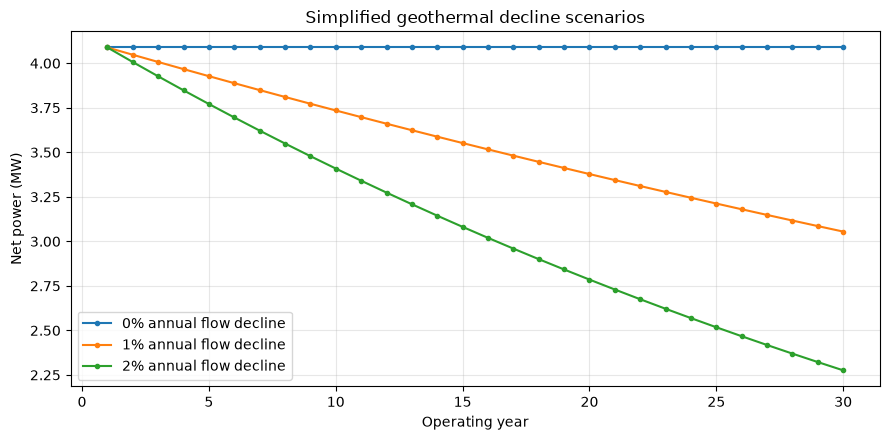

In [3]:
years = np.arange(1, 31)
initial_mass_flow = 90.0
decline_rates = [0.00, 0.01, 0.02]

fig, ax = plt.subplots(figsize=(9, 4.5))
for decline in decline_rates:
    flow = initial_mass_flow * (1 - decline) ** (years - 1)
    net_power = geothermal_net_power_mw(
        flow, production_c=165, reinjection_c=70,
        conversion_efficiency=0.13, parasitic_fraction=0.12,
    )
    ax.plot(years, net_power, marker="o", markersize=3,
            label=f"{decline:.0%} annual flow decline")

ax.set(xlabel="Operating year", ylabel="Net power (MW)",
       title="Simplified geothermal decline scenarios")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

The plot varies only mass flow. In a real reservoir, temperature, pressure, scaling, downtime, reinjection response, and parasitic pumping may also change.

[Download the theory notebook](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/generated/assets/section6/geothermalEnergy.ipynb).

## Common mistakes

- Using °C rather than Kelvin in a thermodynamic temperature ratio.
- Calling geothermal gradient a heat flux.
- Ignoring phase change when enthalpy, not constant $c_p\Delta T$, is required.
- Reporting gross power while omitting pumping and auxiliary loads.
- Treating a high subsurface temperature as proof of permeability, flow, or commercial viability.
- Subtracting a fixed decline percentage linearly instead of compounding the retained fraction.

(geothermal-practice)=
## Practice

[Open the geothermal exercises](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section7%2Fworkbook%2Fgeothermal.md) in the Applied Python Workbook.

## Check your understanding

Continue with the [geothermal quiz](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/#lesson=section7%2FrenewableEnergyquizzes%2FgeothermalEnergy.md).

## Drilling a geothermal well: fluid and hydraulics

Drilling creates the borehole; its circulation system must remove rock cuttings, cool the bit and drill string, and help manage pressure. In **direct circulation**, pumps send fluid down the drill pipe, through the bit and back up the annulus between pipe and borehole. Surface equipment separates cuttings before the fluid is recirculated. Dayan (2014) describes water-based muds, air and aerated fluids, and explains the trade-offs among hole cleaning, circulation losses, formation damage and well control [Dayan, 2014](#reference-dayan2014drilling).

In the [drilling explorer](https://roderickperez.github.io/EAGE_PythonRenewableEnergyCourse/sandbox/generated/geothermal-lab/drilling.html), blue beads illustrate downflow in the pipe and gold beads show the estimated cuttings direction in the annulus when the Stokes model is applicable. The three-dimensional plot shows hydrostatic pressure in blue and circulating pressure in red against vertical depth. Select depth, flow, diameters, fluid density and viscosity, and a **prescribed annular friction loss**. Changes to flow do not automatically recalculate that loss: it is a separate illustrative input. The visualization is schematic, not to scale.

### Annular velocity and cuttings

For concentric circular sections, hole diameter $D_h$ and pipe outside diameter $D_p$ in metres, volumetric circulation rate $Q$ in m³/s, and an incompressible single-phase fluid,

$$A_a=\frac{\pi}{4}(D_h^2-D_p^2), \qquad v_a=\frac{Q}{A_a}.$$

The annular area $A_a$ is m² and average annular velocity $v_a$ is m/s. The explorer converts L/min to m³/s by dividing by 60,000. In the simplified vertical model, cuttings transport velocity is $v_t=v_a-v_s$, where $v_s$ is the settling or slip velocity relative to fluid. Flow direction, inclination, rotation, cuttings beds, shape, concentration, fluid rheology and temperature complicate real hole cleaning [Dayan, 2014](#reference-dayan2014drilling).

For an isolated sphere in a Newtonian fluid under creeping-flow assumptions, Stokes' ideal settling estimate and its particle Reynolds number are

$$v_s=\frac{(\rho_s-\rho_f)gd_s^2}{18\mu},\qquad Re_p=\frac{\rho_f v_s d_s}{\mu}.$$

$\rho_s$ and $\rho_f$ are particle and fluid density (kg/m³), $d_s$ is diameter (m), $\mu$ is dynamic viscosity (Pa s), and $g=9.80665$ m/s². The explorer uses a synthetic particle density of 2,650 kg/m³ and suppresses the estimate if $Re_p\ge1$. It is not valid for arbitrary particles, non-Newtonian mud or high-Reynolds conditions, and it is **not** an operational hole-cleaning decision rule. A negative ideal transport velocity is a model result, not a complete prediction of a cuttings bed. **Reading caution:** Dayan’s Eq. 5, p. 129, includes a factor of 928.2 alongside quantities labelled in SI units. For the SI units stated here, use the Reynolds expression above without that factor; see the [NASA Reynolds-number definition](https://www.grc.nasa.gov/www/k-12/airplane/reynolds.html).

### Hydrostatic and circulating pressure

For a constant-density single-phase fluid, true vertical depth $z$, a surface gauge pressure of zero, and an explicitly supplied annular frictional pressure drop $\Delta p_a$ over that depth,

$$p_h=\rho_fgz,\quad p_{circ}=p_h+\Delta p_a,\quad \rho_{ECD}=\rho_f+\frac{\Delta p_a}{gz}.$$

These SI equations express the hydrostatic, circulating-pressure and equivalent-circulating-density ideas discussed by Dayan. Pressure is in Pa, depth is in metres and ECD is kg/m³. The explorer assumes the specified total annular friction is distributed uniformly along depth for its red plotted line. Actual annular loss depends on geometry, flow, fluid rheology and other conditions; it is not total pump pressure, which also includes pipe, bit and surface losses. Gas expansion, thermal effects, pressure transients and formation flow are not represented [Dayan, 2014](#reference-dayan2014drilling).

For a simple water-bentonite Bingham interpretation using conventional 600 and 300 rpm viscometer readings, $PV=\theta_{600}-\theta_{300}$ in cP and $YP=\theta_{300}-PV$ in the standard field convention (lbf/100 ft²). This is a rheological model, not a direct substitution for Newtonian viscosity in the Stokes estimate. Gel strength and filtration are additional measured properties. Temperature changes, solids and additives affect fluid behavior; aerated fluids require multiphase treatment [Dayan, 2014](#reference-dayan2014drilling).

Dayan's Eqs. 51–52 (p. 145) label the corresponding yield-point result in dyn/cm². Do not transfer the same numerical value between that label and the field unit without conversion: 1 lbf/100 ft² is approximately 4.788 dyn/cm², so 10 lbf/100 ft² is approximately 47.88 dyn/cm². Confirm the instrument's calibration and unit convention before comparing results.

### Check the units in Python

In [4]:
import math
depth, density, annular_loss = 2000.0, 1100.0, 1.0e6  # m TVD, kg/m³, Pa
hole, pipe, flow_l_min = 0.215, 0.125, 1200.0        # m, m, L/min
area = math.pi * (hole**2 - pipe**2) / 4
velocity = (flow_l_min / 60000) / area
hydrostatic = density * 9.80665 * depth
ecd = density + annular_loss / (9.80665 * depth)
print(f'Annular velocity: {velocity:.3f} m/s')
print(f'Hydrostatic pressure: {hydrostatic / 1e6:.3f} MPa')
print(f'Circulating pressure: {(hydrostatic + annular_loss) / 1e6:.3f} MPa')
print(f'ECD: {ecd:.1f} kg/m³')

Annular velocity: 0.832 m/s
Hydrostatic pressure: 21.575 MPa
Circulating pressure: 22.575 MPa
ECD: 1151.0 kg/m³


**Investigate:** Hold geometry fixed and double the flow rate. What happens to annular velocity? Then change only the prescribed friction loss: which pressure and ECD values change? Compare the fluid types and their functions in Dayan's report, and identify which measurements would be needed before applying a real drilling program.

The explorer is a simplified educational calculation. It does not calculate pore pressure, fracture pressure, well stability, fluid losses, gas influx, temperature-dependent properties, complete pump pressure or operational safety margins. It must not be used to select an actual mud program or operate a well. Actual geothermal drilling requires site-specific engineering and approved well-control procedures.

## References used in this notebook

<a id="reference-dayan2014drilling"></a>

- **dayan2014drilling:** Dayan, George Moshe. Drilling Fluid Design for Geothermal Wells (2014). https://www.grocentre.is/gtp/media-gtp/publication/publication-dashboard/drilling-fluid-design-for-geothermal-wells
<a id="reference-white2024closedloop"></a>

- **white2024closedloop:** White, Mark and Vasyliv, Yaroslav and Beckers, Koenraad and others. Numerical investigation of closed-loop geothermal systems in deep geothermal reservoirs (2024). https://doi.org/10.1016/j.geothermics.2023.102852
<a id="reference-diPippo2016geothermal"></a>

- **diPippo2016geothermal:** DiPippo, Ronald. Geothermal Power Plants: Principles, Applications, Case Studies and Environmental Impact (2016). Edition 4. https://www.sciencedirect.com/book/monograph/9780081008799/geothermal-power-plants
<a id="reference-doeGeothermalElectricity"></a>

- **doeGeothermalElectricity:** U.S. Department of Energy. Geothermal Electricity Generation (2014). https://www.energy.gov/hgeo/geothermal/geothermal-electricity-generation DOE page metadata: originally published 2014; modified 2026-07-13. Accessed 2026-09-01.
<a id="reference-doeEGS"></a>

- **doeEGS:** U.S. Department of Energy. Enhanced Geothermal Systems (2014). https://www.energy.gov/hgeo/geothermal/enhanced-geothermal-systems
<a id="reference-grant2011"></a>

- **grant2011:** Grant, Malcolm A. and Bixley, Paul F. Geothermal Reservoir Engineering (2011). Edition 2. https://www.sciencedirect.com/book/9780123838803/geothermal-reservoir-engineering
<a id="reference-jica2011"></a>

- **jica2011:** Japan International Cooperation Agency. Guideline and Manual for Hydropower Development, Vol. 2: Small Scale Hydropower (2011). https://openjicareport.jica.go.jp/643/643/643_000_12024899.html
<a id="reference-wade2003"></a>

- **wade2003:** Wade, Herbert A. Solar Photovoltaic Systems: Technical Training Manual (2003). https://pcreee.org/publication/solar-photovoltaic-systems-technical-training-manual
<a id="reference-foster2010"></a>

- **foster2010:** Foster, Robert and Ghassemi, Majid and Cota, Alma. Solar Energy: Renewable Energy and the Environment (2010). Edition 1. https://www.routledge.com/Solar-Energy-Renewable-Energy-and-the-Environment-1st-Edition/Foster-Ghassemi-Cota/p/book/9780429139895